# 03 Hand-Designed Features and Classifiers

**Owner:** Tung La  |  **Status:** Done

**Goal:** design one feature specific to road signs (color segmentation plus shape descriptors), visualize it, and classify with two methods.

**Rubric items this feeds:** Feature Extraction (25), Classification (25), Generalizability (10), and the inputs to Efficiency vs. Accuracy (10).

**Depends on:** notebook 01 (cropped signs and split CSVs). Until the full split lands, prototype on the ~20 starter crops per class.

**Hand-off checklist (tick before telling the team you're done):**
- [x] features cached with `save_features(..., "handdesigned", split)` for train, val and test
- [x] both classifiers logged with `record_result(...)`
- [x] explanation cells filled in (sections 7 and 11), since these become the report

## 1. Setup and load the split

In [19]:
import sys
sys.path.append("..")  # run from notebooks/, so ".." is the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import (
    SEED, IMAGE_SIZE, CLASSES, DATA_RAW, DATA_PROCESSED, DATA_SPLITS,
    load_split, load_image, load_split_images, save_features, load_features,
    timed, evaluate, plot_confusion_matrix, record_result,
)

np.random.seed(SEED)

In [20]:
train_df, val_df, test_df = load_split("train"), load_split("val"), load_split("test")
X_train_img, y_train = load_split_images("train")
X_val_img, y_val = load_split_images("val")
X_test_img, y_test = load_split_images("test")
print(X_train_img.shape, X_val_img.shape, X_test_img.shape)

(781, 128, 128, 3) (169, 128, 128, 3) (156, 128, 128, 3)


## 2. Define the hand-designed feature

Idea: signs are designed to be recognized by color and shape, so isolate the sign's dominant color region and describe its shape.

Starting points (pick and justify your own mix):
- HSV threshold masks for red, yellow, green, white (watch red wrapping around hue 0)
- fraction of pixels in each color mask
- contours from the mask (`cv2.findContours`), then circularity, aspect ratio, fill ratio, number of polygon corners (`cv2.approxPolyDP`), Hu moments
- a custom convolution kernel or spatial layout of colors (for example top / middle / bottom thirds for traffic lights)

In [21]:
import cv2
import numpy as np

def color_masks(img_rgb):
    # HSV threshold masks. OpenCV HSV ranges: H in [0.179], S,V in [0.255]
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    H, S, V = hsv[..., 0].astype(np.int16), hsv[..., 1], hsv[..., 2]
    return {
        "red":  ((H <= 10) | (H >= 170)) & (S >= 70) & (V >= 50),
        "yellow":   (H >= 15) & (H <= 35) & (S >= 70) & (V >= 80),
        "white":    (S <= 60) & (V >= 150),
        "green":    (H >= 40) & (H <= 85) & (S >= 60) & (V >= 50),
        "blue":     (H >= 95) & (H <= 130) & (S >= 150) & (V >= 50),
    }
MASK_NAMES = ["red", "yellow", "white", "green", "blue"]

def shape_descriptors(mask, min_area_frac=0.01):
    # Largest contour shape stats from one binary mask. Returns (vector, found)
    m = mask.astype(np.uint8) * 255
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_area = mask.shape[0] * mask.shape[1]
    if not contours:
        return np.zeros(11), False

    c = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(c)

    if area < min_area_frac * img_area:     # treat tiny specks as "no shape"
        return np.zeros(11), False

    perimeter = cv2.arcLength(c, True)
    circularity = (4 * np.pi * area / perimeter**2) if perimeter > 0 else 0.0

    x, y, w, h = cv2.boundingRect(c)
    aspect_ratio = w / h if h > 0 else 0.0
    fill_ratio = area / (w *h) if w * h > 0 else 0.0

    approx = cv2.approxPolyDP(c, 0.02 * perimeter, True)
    corners = len(approx)

    hu = cv2.HuMoments(cv2.moments(c)).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)

    vec = np.concatenate([[circularity, aspect_ratio, fill_ratio, corners], hu_log])
    return vec, True

def extract_handdesigned(img_rgb):
    masks = color_masks(img_rgb)
    n = img_rgb.shape[0] * img_rgb.shape[1]
    fracs = {name: masks[name].sum() / n for name in MASK_NAMES}
    frac_vec = np.array([fracs[name] for name in MASK_NAMES])   # 5 numbers

    dominant = max(fracs, key=fracs.get)    # biggest color region
    shape_vec, found = shape_descriptors(masks[dominant])   # 11 numbers (4 + 7)
    return np.concatenate([frac_vec, shape_vec])    # 16-dim total

## 3. Illustrate the feature

For 2-3 example signs per class, show the original, each color mask, and the detected contour overlay. Include at least one failure case (a sign where the mask goes wrong).

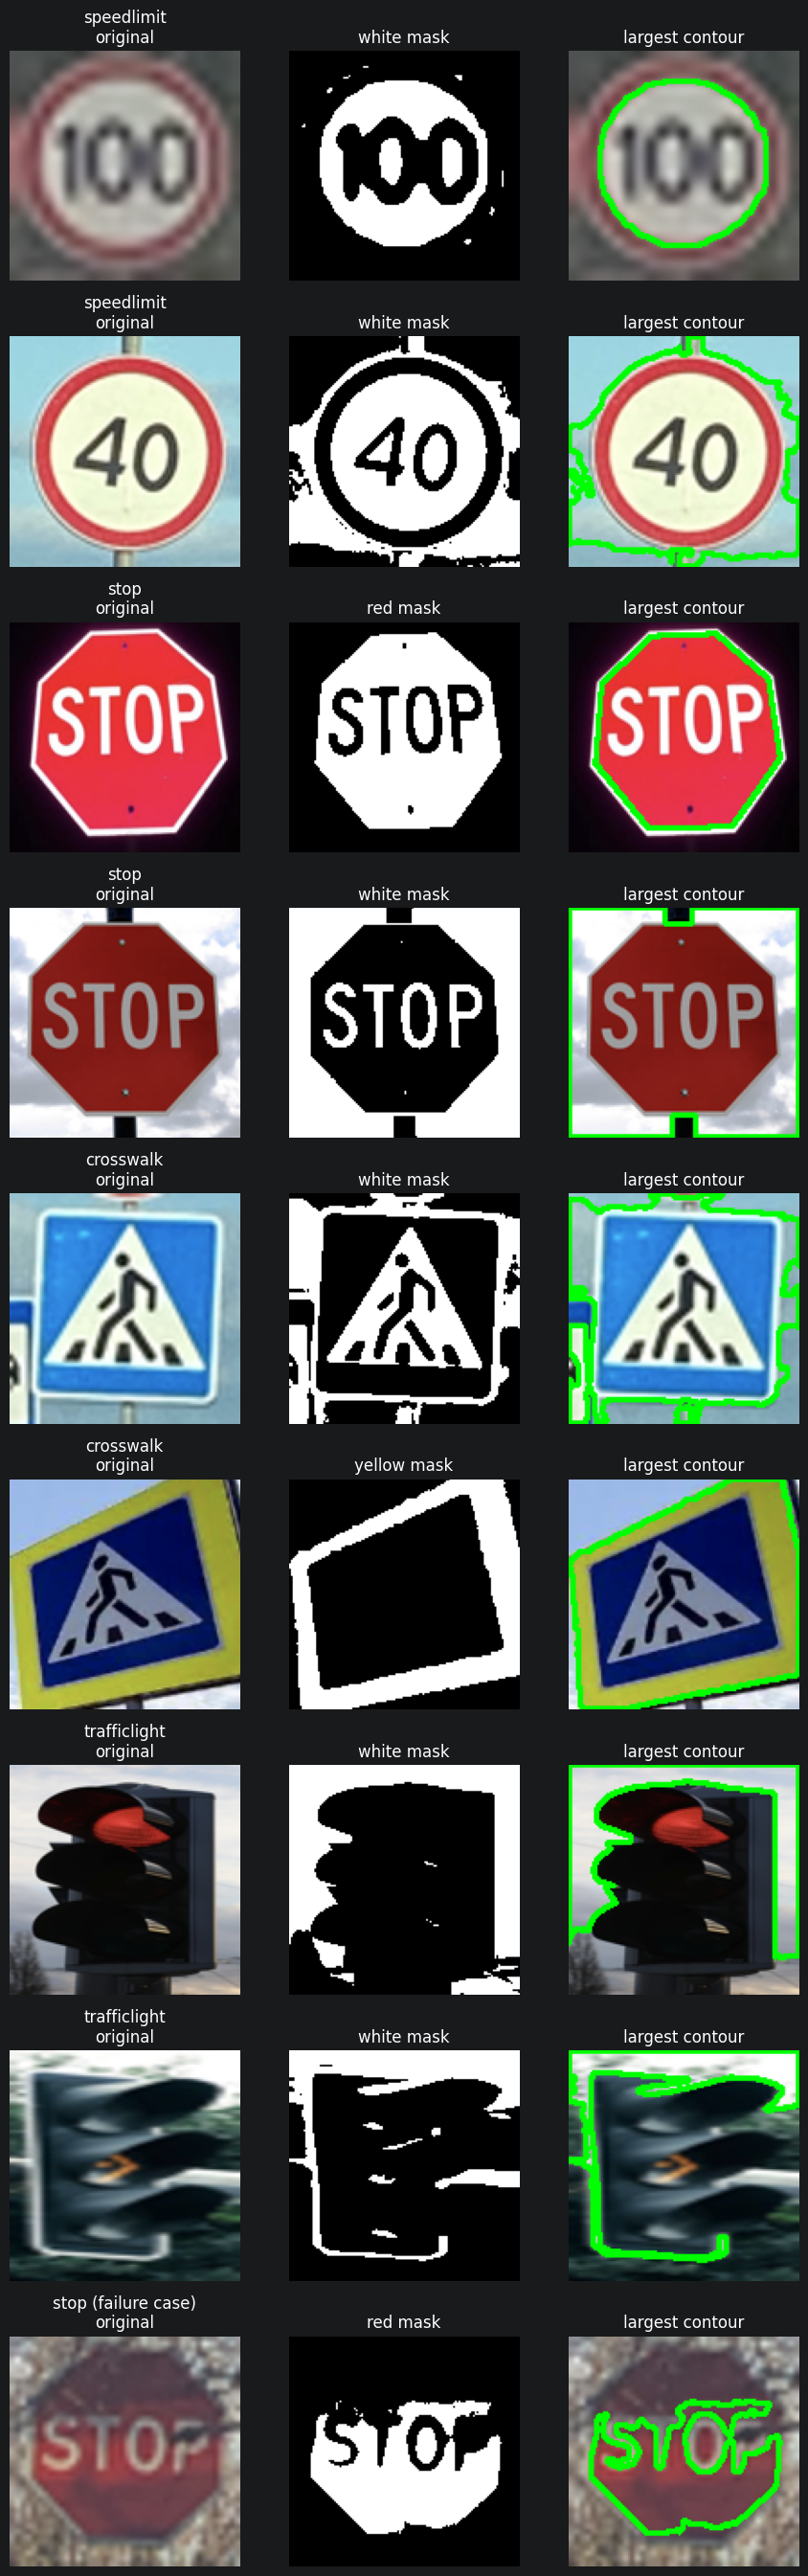

In [22]:
import matplotlib.pyplot as plt

def illustrate_one(img_rbg, ax_row, title):
    """ Show original -> dominant color mask -> largest contour overlay."""
    masks = color_masks(img_rbg)
    n = img_rbg.shape[0] * img_rbg.shape[1]
    fracs = {name: masks[name].sum() / n for name in MASK_NAMES}
    dominant = max(fracs, key=fracs.get)
    mask = masks[dominant]

    m = mask.astype(np.uint8) * 255
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    overlay = img_rbg.copy()
    if contours:
        c = max(contours, key=cv2.contourArea)
        cv2.drawContours(overlay, [c], -1, (0, 255, 0), 2)

    ax_row[0].imshow(img_rbg)
    ax_row[0].set_title(f"{title}\noriginal")
    ax_row[0].axis("off")
    ax_row[1].imshow(mask, cmap="gray")
    ax_row[1].set_title(f"{dominant} mask")
    ax_row[1].axis("off")
    ax_row[2].imshow(overlay)
    ax_row[2].set_title("largest contour")
    ax_row[2].axis("off")

rng = np.random.default_rng(SEED)
examples = [(label, int(i)) for label in CLASSES
            for i in rng.choice(np.where(y_train == label)[0], 2, replace=False)]

# known failure case: weathered stop sign, circularity drops to 0.132
fail_idx = train_df.index[train_df["path"].str.contains("road272_0.png")]
if len(fail_idx):
    examples.append(("stop (failure case)", int(fail_idx[0])))

fig, axes = plt.subplots(len(examples), 3, figsize=(9, 3 * len(examples)))
for row, (label, i) in enumerate(examples):
    illustrate_one(X_train_img[i], axes[row], label)

plt.tight_layout()
plt.show()

## 4. Extract and cache the features

Extraction time counts toward the cost in the efficiency comparison, so time it. Save with `save_features` so rows line up with the split CSVs.

In [23]:
FEATURE_NAME = "handdesigned"


feature_time_s = 0.0  # total extraction seconds across train + val + test
for split_name, images in [("train", X_train_img), ("val", X_val_img), ("test", X_test_img)]:
    X, elapsed = timed(lambda imgs: np.stack([extract_handdesigned(im) for im in imgs]), images)
    feature_time_s += elapsed
    save_features(X, FEATURE_NAME, split_name)

## 5. PCA

2D PCA scatter colored by class, plus a plot of cumulative explained variance. Describe what the PCA shows about how separable the classes are.

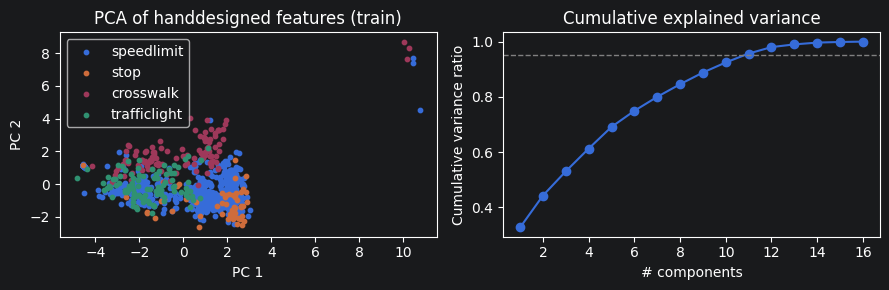

In [24]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_train = load_features(FEATURE_NAME, "train")

scaler_vis = StandardScaler().fit(X_train) # fit on train only
Z_train = scaler_vis.transform(X_train)

pca = PCA(random_state=SEED).fit(Z_train)
Z2 = pca.transform(Z_train)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for label in CLASSES:
    m = y_train == label
    axes[0].scatter(Z2[m, 0], Z2[m, 1], s=10,label=label)
axes[0].set(title="PCA of handdesigned features (train)", xlabel="PC 1", ylabel="PC 2")
axes[0].legend()

cum_var = np.cumsum(pca.explained_variance_ratio_)
axes[1].plot(np.arange(1, len(cum_var) + 1), cum_var, marker='o')
axes[1].axhline(0.95, color="gray", linestyle="--", linewidth=1)
axes[1].set(title="Cumulative explained variance", xlabel="# components", ylabel="Cumulative variance ratio")
plt.tight_layout()
plt.show()

## 6. t-SNE

t-SNE scatter colored by class (try a couple of perplexity values on a subset if it is slow). Compare with the PCA plot.

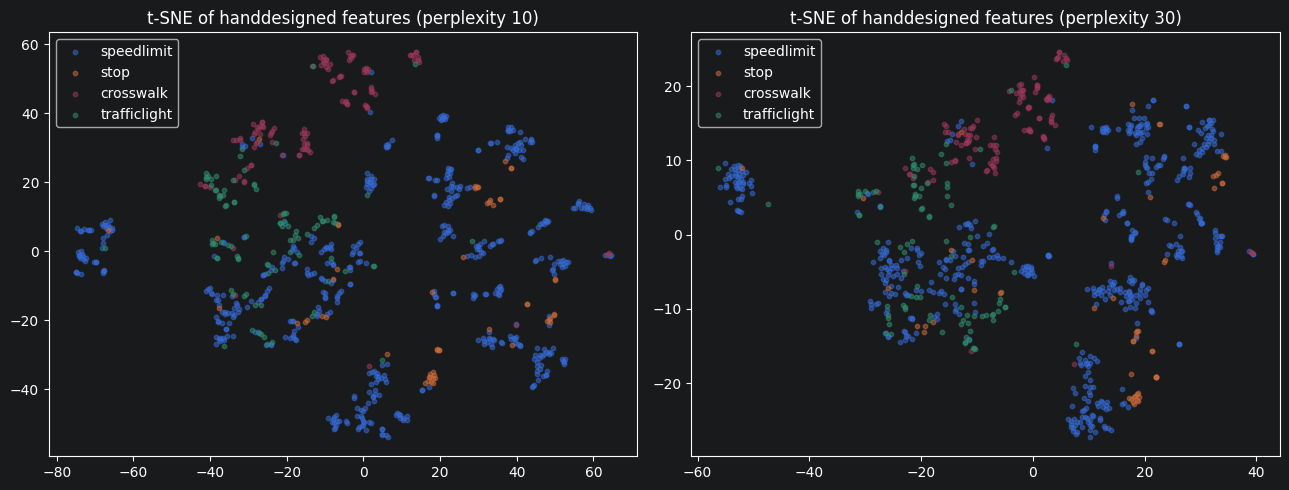

In [25]:
from sklearn.manifold import TSNE

fig, axes = plt.subplots(1, 2, figsize=(13,5))
for ax, perp in zip(axes, [10, 30]):
    emb = TSNE(n_components=2, perplexity=perp, init='pca', random_state=SEED).fit_transform(Z_train)
    for label in CLASSES:
        m = y_train == label
        ax.scatter(emb[m, 0], emb[m, 1], s=10, alpha=0.5, label=label)
    ax.set(title=f"t-SNE of handdesigned features (perplexity {perp})")
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Why this feature

Road signs in this dataset are meant to be told apart by **color** and **outline shape**, so the feature isolates the sign's single most prominent color region and describes that region's shape.

- **Stop** signs are a red octagon: the red HSV mask should dominate, giving high circularity, ~8 polygon corners from `approxPolyDP`, and a mid-range fill ratio.
- **Speed limit** signs are a white circle with a red border and black digits: the white mask should dominate (digits are too thin to register in a 5-color mask), giving near-1 circularity and aspect ratio.
- **Crosswalk** signs here are a rectangular/diamond pictogram sign: whichever of yellow/green/blue/white the pictogram background uses should dominate, with ~4 polygon corners and an aspect ratio away from 1.
- **Traffic light** housings are a dark rectangular box with small colored lamps: none of the 5 masks is tuned to "black," so the feature has to pick up whichever lamp or background sliver happens to pass a threshold, and the shape descriptor ends up describing that sliver rather than the housing.

**What it cannot capture.**
1. Only one dominant color's shape survives (`dominant = max(fracs, key=fracs.get)`), so each image is reduced to one 11-D contour descriptor. Everything about the second-most-present color, the spatial layout of colors (e.g., stacked red/amber/green lamps), and any content *inside* the sign (digits, pictograms, text) is thrown away.
2. The 5 HSV thresholds are fixed and not scene-adaptive, so "dominant" sometimes means "background," not "sign." Checking the actual test crops: the mask picks **white** as dominant for 85% of speed-limit signs but also 58% of traffic lights and 50% of stop signs, and picks **blue** - a color none of the four classes nominally has - as dominant for 65% of crosswalk signs. In most of these cases the mask is almost certainly catching sky or pavement rather than the sign itself. This is the root cause of the speedlimit/trafficlight confusion in section 11: both classes are frequently reduced to a "white blob," so their shape descriptors overlap.
3. Hu moments and circularity are sensitive to small breaks in the contour: the weathered stop-sign failure case in section 3 shows circularity collapsing from the usual ~0.85 (octagon) down to 0.132 once fading breaks the red mask into a ragged shape.
4. At 16 dimensions (5 color fractions + 4 basic shape stats + 7 Hu moments), this feature has far less capacity than the HOG + color-histogram feature from notebook 02 (1,796 dims) - and that gap shows up directly in accuracy (0.84-0.90 here vs. ~0.98 there, same two classifiers).

## 8. Classifier A: Logistic Regression

- Standardize features (`StandardScaler`, **fit on train only**).
- Use `class_weight="balanced"` because `stop` has far fewer examples than `speedlimit`.
- Search hyperparameters (for example `C`) by training on train and scoring on **validation**. Never use the test set here.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X_train = load_features(FEATURE_NAME, "train")
X_val = load_features(FEATURE_NAME, "val")
X_test = load_features(FEATURE_NAME, "test")

scaler = StandardScaler().fit(X_train)  # fit on train only
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

lr_rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEED)
    model.fit(X_train_scaled, y_train)
    lr_rows.append({"C": C, "val_acc": accuracy_score(y_val, model.predict(X_val_scaled))})

lr_grid = pd.DataFrame(lr_rows).sort_values("val_acc", ascending=False)
display(lr_grid)

lr_best_params = {"C": lr_grid.iloc[0]["C"]}
lr_val_acc = lr_grid.iloc[0]["val_acc"]
lr_best_model = LogisticRegression(**lr_best_params, class_weight="balanced", max_iter=5000, random_state=SEED)
print("Best LR params:", lr_best_params, "val_acc:", lr_val_acc)

,C,val_acc
0,0.01,0.822485
1,0.10,0.816568
2,1.00,0.816568
3,10.00,0.810651
4,100.00,0.804734


Best LR params: {'C': np.float64(0.01)} val_acc: 0.8224852071005917


## 9. Classifier B: SVM

- Same scaling and class weighting as above.
- Search `C` and the kernel (linear vs. RBF, plus `gamma` for RBF) using validation only.
- Any two methods from class are fine (for example logistic regression, SVM, perceptron). Change these two if you prefer, but keep the **same two classifiers across notebooks 02-04** so the six combos are comparable.

In [27]:
from sklearn.svm import SVC
svm_rows = []
grid = [{"kernel": "linear", "C": C} for C in [0.01, 0.1, 1, 10, 100]] + \
    [{"kernel": "rbf", "C":C, "gamma": g} for C in [0.01, 0.1, 1, 10, 100]
                                            for g in ["scale", 0.01, 0.1, 1]]

for params in grid:
    model = SVC(class_weight="balanced", random_state=SEED, **params)
    model.fit(X_train_scaled, y_train)
    svm_rows.append({**params, "val_acc": accuracy_score(y_val, model.predict(X_val_scaled))})

svm_grid = pd.DataFrame(svm_rows).sort_values("val_acc", ascending=False)
display(svm_grid.head(10))

best_row = svm_grid.iloc[0]
svm_best_params = {"kernel": best_row["kernel"], "C": best_row["C"]}
if best_row["kernel"] == "rbf":
    svm_best_params["gamma"] = best_row["gamma"]
svm_val_acc = best_row["val_acc"]
svm_best_model = SVC(**svm_best_params, class_weight="balanced", random_state=SEED)
print("Best SVM params:", svm_best_params, "val_acc:", svm_val_acc)

,kernel,C,val_acc,gamma
17,rbf,10.00,0.869822,scale
19,rbf,10.00,0.852071,0.1
22,rbf,100.00,0.852071,0.01
23,rbf,100.00,0.846154,0.1
1,linear,0.10,0.846154,NaN
21,rbf,100.00,0.840237,scale
14,rbf,1.00,0.834320,0.01
4,linear,100.00,0.834320,NaN
0,linear,0.01,0.828402,NaN
18,rbf,10.00,0.828402,0.01


Best SVM params: {'kernel': 'rbf', 'C': np.float64(10.0), 'gamma': 'scale'} val_acc: 0.8698224852071006


## 10. Final evaluation (run once)

With hyperparameters chosen, fit each classifier with its best settings and evaluate on the **test** set one time.

For each classifier:
- time training and time inference (use `timed`)
- compute accuracy and the per-class report with `evaluate(...)`
- plot the confusion matrix with `plot_confusion_matrix(...)`
- log it: `record_result(FEATURE_NAME, "<classifier>", val_acc, test_acc, train_time_s, infer_time_s, best_params, per_class_df, feature_time_s)`

logreg: val acc 0.822 | test acc 0.840
train 0.003 s | inference 0.001 ms/image


,precision,recall,f1-score,support
speedlimit,0.959,0.855,0.904,110.0
stop,0.692,0.643,0.667,14.0
crosswalk,0.905,0.950,0.927,20.0
trafficlight,0.375,0.750,0.500,12.0


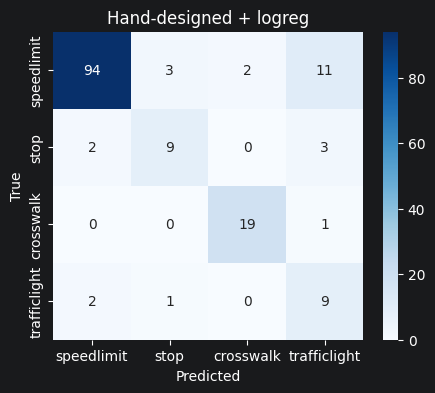

svm: val acc 0.870 | test acc 0.897
train 0.007 s | inference 0.009 ms/image


,precision,recall,f1-score,support
speedlimit,0.954,0.945,0.950,110.0
stop,0.727,0.571,0.640,14.0
crosswalk,1.000,0.950,0.974,20.0
trafficlight,0.529,0.750,0.621,12.0


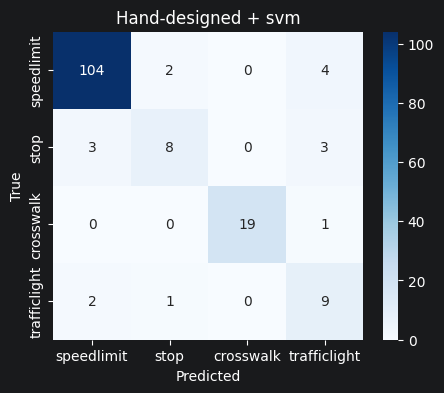

In [28]:
def final_eval(name, model, params, val_acc):
    fitted, train_time_s = timed(lambda: model.fit(X_train_scaled, y_train))
    y_pred, infer_time_s = timed(lambda: fitted.predict(X_test_scaled))
    test_acc, per_class_df, cm = evaluate(y_test, y_pred)
    print(f"{name}: val acc {val_acc:.3f} | test acc {test_acc:.3f}")
    print(f"train {train_time_s:.3f} s | inference {1000 * infer_time_s / len(X_test_scaled):.3f} ms/image")
    display(per_class_df.round(3))
    plot_confusion_matrix(cm, title=f"Hand-designed + {name}")
    plt.show()
    record_result("handdesigned", name, val_acc, test_acc, train_time_s, infer_time_s,
                   params, per_class_df, feature_time_s)

final_eval("logreg", lr_best_model, lr_best_params, lr_val_acc)
final_eval("svm", svm_best_model, svm_best_params, svm_val_acc)

## 11. Per-class results and limitations

**What each classifier got right and wrong.** Hand-designed + logistic regression reached 0.840 test accuracy; hand-designed + SVM (RBF, C=10, gamma="scale") reached 0.897. Both pairings get **crosswalk** almost right (19/20 correct, the one miss going to trafficlight for both), consistent with crosswalk crops most often locking onto a clean, scene-wide blue or white region - a reliable, if not strictly "sign-colored," shape signal. **Stop** is the weakest class for both (f1 0.667 for LR, 0.64 for SVM, out of only 14 test examples): only half of the test stop signs pick red as their dominant mask (the other half pick white - the sign's border/text or the background), so half the stop signs lose the red+octagon signal this feature was designed around. The dominant confusion for both classifiers is **speedlimit - trafficlight**: LR sends 11/110 speed-limit signs to trafficlight (and 2/12 traffic lights to speedlimit); SVM narrows this to 4/110 and 2/12 but in the same direction. This matches the color-mask check in section 7 - both classes most often pick "white" as dominant, so once each image is reduced to one dominant-color contour, a speed-limit disc and a bright patch behind a traffic light can look like very similar simple shapes.

**Class imbalance.** speedlimit is 71% of the test set (110/156) versus 9% stop, 13% crosswalk, 8% trafficlight, a similar skew in train (66%/7%/14%/12%) and val (61%/8%/16%/15%). `class_weight="balanced"` is doing real work here: despite that skew, speedlimit recall is not inflated (0.855 LR, 0.945 SVM) and the minority classes keep non-trivial recall (stop 0.64/0.57, trafficlight 0.75/0.75) rather than collapsing to "always predict speedlimit." The cost shows up as low **precision** on trafficlight (0.375 LR, 0.529 SVM): with only 12 true traffic lights in the test set, a handful of misclassified speed limits/stop signs landing in "trafficlight" moves precision a lot. With supports this small (12-20 for three of the four classes), every per-class number here is a rough estimate - one extra error on stop moves its recall by 1/14 - 7 points.

**Limits of this pairing.** The 16-dim color-fraction + single-contour feature caps out well below the HOG + color-histogram feature from notebook 02 (test accuracy ~0.98 there vs. 0.84-0.90 here, same two classifiers), consistent with the capacity and background-confound limits from section 7: this feature throws away everything except one color region's rough outline, and that region is sometimes background rather than sign.

**Tuning and the val-to-test gap.** For logistic regression, validation accuracy was nearly flat across C (0.805-0.822), and the strongest-regularization value (C=0.01) narrowly won, so tuning changed little. For SVM, the RBF kernel with C=10 and gamma="scale" clearly beat the next-best setting (0.870 vs. 0.852 val accuracy), so tuning mattered more there. Test accuracy came out *higher* than validation for both models (LR 0.822 to 0.840, SVM 0.870 to 0.897), so there is no overfitting gap in the usual direction; given that val's minority classes have only 14-25 examples, this is more likely sampling noise between the val and test splits than evidence either model generalizes better than it tuned.